# Entraîner YOLO sur les plannings FlexiStaff, pas à pas

Ce notebook suit le jour 1 du cas pratique : du dataset annoté dans CVAT jusqu'au premier modèle tracé dans MLflow.

```
dataset annoté  →  vérifications  →  test rapide  →  vrai run v1 (MLflow)  →  lecture des résultats  →  champion
```

**Comment l'utiliser** : lance les cellules dans l'ordre (`Shift+Entrée`) et lis l'explication avant chaque cellule de code.
Le noyau à choisir en haut à droite est **`.venv` (Python 3.12)**, l'environnement du projet.

## 1. Vérifier l'environnement

On contrôle trois choses :
- qu'on utilise bien le Python **du projet** (3.12, dans `.venv`), et pas le 3.9 du Mac ;
- que PyTorch, la bibliothèque qui fait les calculs du réseau de neurones, est installé ;
- que PyTorch voit le **GPU Apple**. Sur Mac, il y accède par **MPS** (*Metal Performance Shaders*), l'équivalent Apple de CUDA chez NVIDIA.

Si MPS affiche `False`, l'entraînement tournerait sur le processeur, en beaucoup plus lent.

In [1]:
import os
import sys

import torch

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"  # coupe un message d'aide de MLflow qui encombre les sorties

print("Python  :", sys.version.split()[0], "→", sys.executable)
print("PyTorch :", torch.__version__)
print("GPU Apple (MPS) disponible :", torch.backends.mps.is_available())

Python  : 3.12.16 → /Users/bediee/Dev/flexistaff_team_magma/.venv/bin/python
PyTorch : 2.15.0
GPU Apple (MPS) disponible : True


## 2. Où sont les fichiers

Le notebook est rangé dans `ai_training/`, donc la racine du dépôt est le dossier juste au-dessus.

`data.yaml` est la **carte du dataset** pour YOLO :
- `path` : le dossier racine du dataset ;
- `train` et `val` : où sont les images, relativement à `path` ;
- `names` : le nom de chaque numéro de classe. L'ordre doit être celui de l'export CVAT.

In [2]:
from pathlib import Path

ROOT = Path.cwd().parent  # racine du dépôt flexistaff_team_magma

# ---- Dataset du run : une seule ligne active (sans #) ----
#DATASET = ROOT / "dataset" / "team_magma_lot_corrige"   # runs A et B : 31 vraies images
#DATASET = ROOT / "dataset" / "team_magma_synth200"    # run C : 31 vraies + 200 synthétiques
DATASET = ROOT / "dataset" / "team_magma_synth300"    # run D : 31 vraies + 300 synthétiques

DATA_YAML = DATASET / "data.yaml"

print(DATA_YAML.read_text())

path: /Users/bediee/Dev/flexistaff_team_magma/dataset/team_magma_synth300
train: images/train
val: images/val
names:
  0: Date
  1: Cellule
  2: Nom
  3: Titre
  4: Cellule_code



## 3. Le format des labels YOLO

Chaque image `img001.jpg` a un fichier `img001.txt` du même nom, avec **une ligne par boîte** :

```
classe  x_centre  y_centre  largeur  hauteur
```

Les coordonnées sont **normalisées** entre 0 et 1, c'est-à-dire divisées par la taille de l'image.
`0.5` veut dire « au milieu ». Les labels restent donc valables quand YOLO redimensionne l'image.

YOLO trouve le label d'une image en remplaçant `/images/` par `/labels/` et `.jpg` par `.txt` dans son chemin.

In [3]:
CLASS_NAMES = ["Date", "Cellule", "Nom", "Titre", "Cellule_code"]  # même ordre que data.yaml


def label_path_for(image_path):
    """Donne le chemin du label d'une image, avec la même règle que YOLO."""
    return Path(str(image_path).replace("/images/", "/labels/")).with_suffix(".txt")


example = sorted((DATASET / "images" / "train").rglob("*.jpg"))[0]
print("Image :", example.name)
print("Ses 5 premières boîtes :")
for line in label_path_for(example).read_text().splitlines()[:5]:
    class_id = int(line.split()[0])
    print(f"  {line}    ← {CLASS_NAMES[class_id]}")

Image : synth_0000.jpg
Ses 5 premières boîtes :
  0 0.298628 0.272912 0.093059 0.035899    ← Date
  0 0.390888 0.276237 0.092600 0.035827    ← Date
  0 0.482910 0.279553 0.092288 0.035760    ← Date
  0 0.574554 0.282856 0.092125 0.035697    ← Date
  0 0.665889 0.286147 0.091964 0.035635    ← Date


## 4. Vérifier le dataset avant d'entraîner

Un modèle n'est jamais meilleur que ses données. Avant de lancer quoi que ce soit, on compte :
- les images et les labels de chaque lot. **train** sert à apprendre ; **val** contient des images que le modèle ne voit
  jamais pendant l'apprentissage, et c'est sur elles qu'on le note ;
- les images **sans fichier de label**. YOLO les prend pour des images « sans rien à détecter ». Si ce sont de vrais
  plannings non annotés, le modèle apprend que des cellules sont du fond, et il se dégrade ;
- le nombre de boîtes par classe. Une classe rare sera plus difficile à apprendre.

In [4]:
from collections import Counter

for split in ["train", "val"]:
    images = sorted((DATASET / "images" / split).rglob("*.jpg"))
    missing = [image.name for image in images if not label_path_for(image).exists()]

    counts = Counter()
    for image in images:
        if label_path_for(image).exists():
            for line in label_path_for(image).read_text().splitlines():
                counts[CLASS_NAMES[int(line.split()[0])]] += 1

    print(f"--- {split} : {len(images)} images")
    print("    sans label :", missing or "aucune")
    for name in CLASS_NAMES:
        print(f"    {name:<13} {counts[name]:>4} boîtes")

--- train : 331 images
    sans label : aucune
    Date          2203 boîtes
    Cellule       6980 boîtes
    Nom           1255 boîtes
    Titre          305 boîtes
    Cellule_code  10504 boîtes
--- val : 8 images
    sans label : aucune
    Date            53 boîtes
    Cellule        214 boîtes
    Nom             39 boîtes
    Titre            5 boîtes
    Cellule_code   190 boîtes


## 5. Voir les annotations sur une image

On redessine les boîtes à partir du fichier `.txt`. C'est le meilleur moyen de repérer une erreur d'annotation
ou de conversion : une boîte décalée ou une mauvaise classe se voient tout de suite.

Pour dessiner, on fait le calcul inverse de la normalisation : on remultiplie par la taille de l'image pour
revenir en pixels, puis on passe du **centre** au **coin haut gauche**.

Change `IMAGE_INDEX` pour regarder d'autres images.

synth_0000.jpg — Date = red, Cellule = blue, Nom = green, Titre = orange, Cellule_code = purple


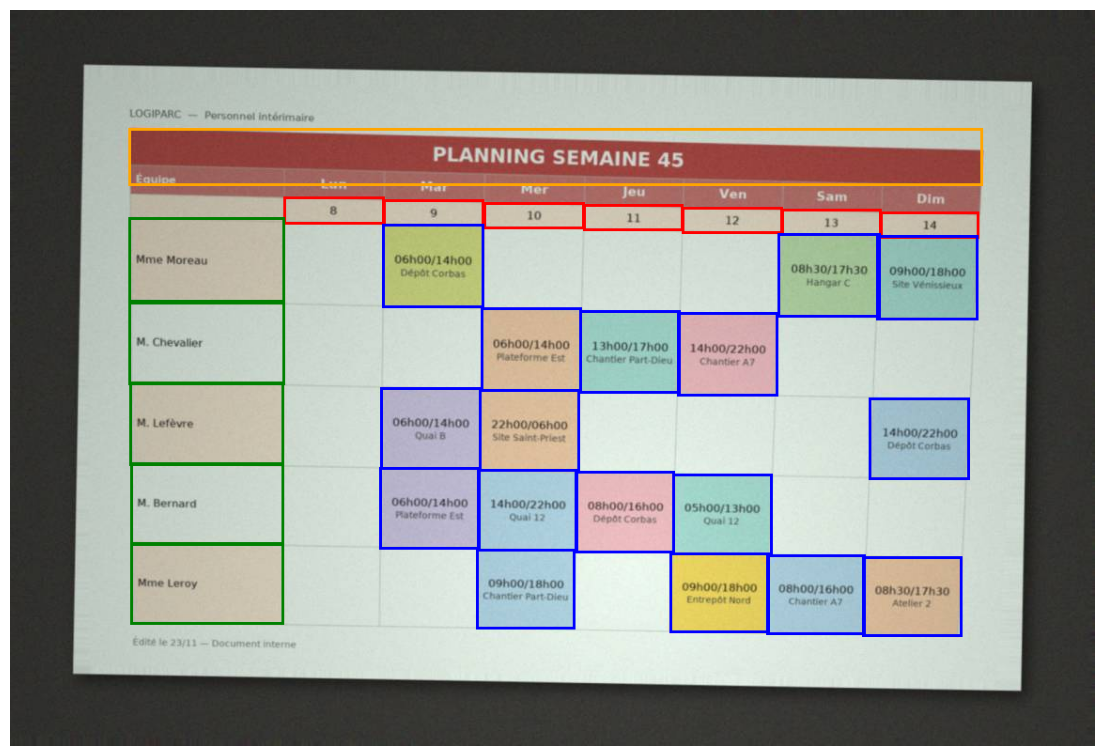

In [5]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

COLORS = ["red", "blue", "green", "orange", "purple"]  # une couleur par classe, dans l'ordre de CLASS_NAMES
IMAGE_INDEX = 0


def draw_labels(image_path):
    """Dessine sur l'image les boîtes de son fichier de labels, une couleur par classe."""
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    draw = ImageDraw.Draw(image)
    for line in label_path_for(image_path).read_text().splitlines():
        class_id, x_center, y_center, box_w, box_h = line.split()
        # Coordonnées normalisées (0 à 1) → pixels
        x_center, box_w = float(x_center) * width, float(box_w) * width
        y_center, box_h = float(y_center) * height, float(box_h) * height
        # YOLO donne le centre ; pour dessiner, il faut le coin haut gauche
        left, top = x_center - box_w / 2, y_center - box_h / 2
        draw.rectangle([left, top, left + box_w, top + box_h], outline=COLORS[int(class_id)], width=3)
    return image


image_path = sorted((DATASET / "images" / "train").rglob("*.jpg"))[IMAGE_INDEX]
print(image_path.name, "—", ", ".join(f"{name} = {color}" for name, color in zip(CLASS_NAMES, COLORS)))
plt.figure(figsize=(14, 14))
plt.imshow(draw_labels(image_path))
plt.axis("off")
plt.show()

## 6. Un test rapide (2 epochs), enregistré en local

Avant le vrai run, on vérifie que toute la chaîne fonctionne (chargement des données, GPU, sauvegarde) sur
**2 epochs**. Une **epoch** correspond à un passage du modèle sur toutes les images d'entraînement.

**Transfer learning** : on ne part pas de zéro. `yolov8s.pt` est un modèle déjà entraîné sur des millions de photos
courantes ; il sait repérer des bords, des formes, des rectangles. On l'**affine** sur nos plannings, ce qui explique
qu'une trentaine d'images suffise pour un premier résultat. Le `s` veut dire *small* ; il existe aussi `n` (nano) et `m` (medium).

**Piège MLflow** : Ultralytics envoie lui-même des informations à MLflow dès que la bibliothèque est installée. Pour
ne pas encombrer l'expérience de l'équipe avec ce test, on l'envoie vers une **petite base MLflow locale**,
dans `runs/`, un dossier ignoré par git.

Les résultats bruts de YOLO (courbes, poids) sont écrits dans `runs/test_rapide*`.

In [6]:
import mlflow
from ultralytics import YOLO

RUNS_DIR = ROOT / "runs"
RUNS_DIR.mkdir(exist_ok=True)

# MLflow local, uniquement pour ce test
mlflow.set_tracking_uri(f"sqlite:///{RUNS_DIR / 'mlflow_test.db'}")
os.environ["MLFLOW_EXPERIMENT_NAME"] = "test_local"

model = YOLO("yolov8s.pt")  # téléchargé au premier lancement
model.train(data=str(DATA_YAML), epochs=2, imgsz=640, device="mps", project=str(RUNS_DIR), name="test_rapide")

Ultralytics 8.4.215 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M5 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/bediee/Dev/flexistaff_team_magma/dataset/team_magma_synth300/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=test_rapide-19, nbs=64, 

/Users/bediee/Dev/flexistaff_team_magma/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/bediee/Dev/flexistaff_team_magma/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Trigge

        1/2       8.4G      1.118      1.871      1.065        449        640: 100% ━━━━━━━━━━━━ 21/21 1.5it/s 13.9s0.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.5it/s 0.2s
                   all          8        499      0.476      0.427      0.301      0.176

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/bediee/Dev/flexistaff_team_magma/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/bediee/Dev/flexistaff_team_magma/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Trigge

        2/2      10.4G     0.7896      1.062     0.9169        789        640: 100% ━━━━━━━━━━━━ 21/21 1.6it/s 13.0s0.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.5it/s 0.2s
                   all          8        499      0.529      0.646      0.588      0.355

2 epochs completed in 0.008 hours.
Optimizer stripped from /Users/bediee/Dev/flexistaff_team_magma/runs/test_rapide-19/weights/last.pt, 22.5MB
Optimizer stripped from /Users/bediee/Dev/flexistaff_team_magma/runs/test_rapide-19/weights/best.pt, 22.5MB

Validating /Users/bediee/Dev/flexistaff_team_magma/runs/test_rapide-19/weights/best.pt...
Ultralytics 8.4.215 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M5 Pro)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.6it/s 0.2s
                   all          8        499  

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x14df9b470>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

**Ce qu'il faut regarder dans la sortie :**
- une ligne qui mentionne `mps` : le GPU est utilisé ;
- les colonnes `box_loss`, `cls_loss`, `dfl_loss` sont les **erreurs** du modèle, et elles doivent baisser ;
  - `box_loss` : les boîtes sont-elles bien placées ?
  - `cls_loss` : la classe est-elle la bonne ?
  - `dfl_loss` : les bords des boîtes sont-ils précis ?
- avec seulement 2 epochs, des métriques proches de 0 sont **normales** : le test sert seulement à vérifier que tout tourne.

S'il n'y a pas d'erreur, on peut passer au vrai run.

## 7. Se connecter au MLflow de la formation

**MLflow** garde la trace de chaque entraînement, et toute l'équipe peut les comparer. Le vocabulaire :
- **expérience** : un classeur. Pour l'équipe, c'est `flexistaff_team-magma` ;
- **run** : un entraînement, nommé `<prénom>_<version>` (ex. `nathalie_v1`) ;
- **paramètres** : ce qu'on a choisi (modèle, epochs, taille d'image) ;
- **métriques** : ce qu'on a obtenu (mAP50, précision, rappel) ;
- **artefacts** : les fichiers produits (`best.pt`, modèle ONNX, courbes).

Les identifiants viennent du fichier `identifiants-<login>.json`, téléchargé depuis ton profil sur le portail.
On le lit à sa place (ici, `~/Downloads`) ; il ne doit **jamais** être copié dans le dépôt, car il contient des mots de passe.

**Sans la VM** (serveur éteint, pas de réseau) : mets `LOCAL = True`. Les runs sont alors rangés sur le Mac, dans
`mlruns/` (ignoré par git), au même endroit que `train.py --local`. Pour les voir, lance dans un terminal :
`.venv/bin/mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db --port 5001`, puis ouvre `http://localhost:5001`.
Ces runs ne sont pas visibles par l'équipe : une fois la VM rallumée, remets `LOCAL = False` et relance à partir d'ici.

In [7]:
import json

SQUAD = "team-magma"
EXPERIMENT = f"flexistaff_{SQUAD}"
LOCAL = False # True : MLflow sur le Mac (VM éteinte) ; False : serveur de la formation

if LOCAL:
    # Même base que train.py --local, pour retrouver tous les essais dans la même interface
    (ROOT / "mlruns").mkdir(exist_ok=True)  # SQLite ne crée pas le dossier tout seul
    tracking_uri = f"sqlite:///{ROOT / 'mlruns' / 'mlflow.db'}"
else:
    # Le fichier d'identifiants est à la racine du dépôt ; le .gitignore (identifiants-*.json) l'empêche de partir sur git
    creds_files = list(ROOT.glob("identifiants-*.json"))
    assert len(creds_files) == 1, f"Il faut exactement un fichier d'identifiants à la racine du projet, trouvé : {creds_files}"
    creds = json.loads(creds_files[0].read_text())["mlflow"]
    os.environ["MLFLOW_TRACKING_USERNAME"] = creds["username"]
    os.environ["MLFLOW_TRACKING_PASSWORD"] = creds["password"]
    tracking_uri = creds["tracking_uri"]

mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment(EXPERIMENT)
os.environ["MLFLOW_EXPERIMENT_NAME"] = EXPERIMENT  # pour qu'Ultralytics reste dans l'expérience de l'équipe

print("Connecté à", tracking_uri, "— expérience :", EXPERIMENT)

Connecté à http://13.37.102.106:5000 — expérience : flexistaff_team-magma


## 8. Le vrai run : `v1`

Les réglages de cette première version sont volontairement simples. Tu les feras varier dans les versions suivantes (v2, v3…).

| Réglage | Valeur | Rôle |
|---|---|---|
| `MODEL` | `yolov8s` | taille du modèle de départ |
| `EPOCHS` | 50 | nombre de passages sur les données |
| `IMGSZ` | 640 | taille (en pixels) à laquelle les images sont redimensionnées. Plus grand : les petites cellules sont mieux vues, mais l'entraînement est plus lent |

À la fin, on enregistre dans le run :
- les **métriques**, calculées sur les images de val :
  - **précision** : parmi les boîtes trouvées, combien sont justes ?
  - **rappel** : parmi les vraies zones, combien ont été trouvées ? Une cellule ratée est un créneau perdu pour l'OCR : c'est le critère n° 1 pour choisir le champion ;
  - **mAP50** : la note globale. Une boîte compte comme juste si elle recouvre la vraie à 50 % ou plus ;
- **`best.pt`** : les poids de la **meilleure** epoch, pas forcément de la dernière ;
- **l'export ONNX** : le format chargé par l'application. Il suffit de `onnxruntime` pour l'utiliser, sans PyTorch.

⏱️ Compte plusieurs minutes. Ultralytics envoie en plus les courbes epoch par epoch dans le même run.

In [ ]:
import onnx
from ultralytics import YOLO, settings

RUNS_DIR = ROOT / "runs"  # résultats bruts de YOLO : runs/<RUN_NAME>

# ---- Réglages du run : un seul bloc actif (sans #), les autres en commentaire ----
# Rappel : la section 2 doit pointer vers le dataset indiqué pour ce run.

# Run A : YOLOv8s, vraies images seules (dataset team_magma_lot_corrige) — environ 4 min
# RUN_NAME = "nathalie_v8s_reel"
# DATASET_VERSION = "v1"
# MODEL = "yolov8s"

# Run B : YOLO26s, vraies images seules (dataset team_magma_lot_corrige) — environ 5 min
# RUN_NAME = "nathalie_y26s_reel"
# DATASET_VERSION = "v1"
# MODEL = "yolo26s"

# Run C : gagnant de A/B, + 200 synthétiques (dataset team_magma_synth200) — environ 30 min
#RUN_NAME = "nathalie_synth200"
#DATASET_VERSION = "v2"
#MODEL = "yolov8s"   # ou "yolo26s" si B a gagné

# Run D : même modèle que C, + 300 synthétiques (dataset team_magma_synth300) — environ 45 min
RUN_NAME = "nathalie_y26s_synth300_960"
DATASET_VERSION = "v2"
MODEL = "yolo26s"   # le même que pour C

# Communs à tous les runs de la battle : on ne les change pas, pour comparer à armes égales
EPOCHS = 100
IMGSZ = 960

# Où tourne l'entraînement : une seule ligne active (sans #)
DEVICE = "mps"    # GPU Apple : rapide (~4 min pour le run A)
#DEVICE = "cpu"  # processeur : environ 4 fois plus lent ; à tester si on soupçonne MPS de fausser les scores

# Le suivi MLflow est fait à la main ci-dessous. On coupe celui intégré à Ultralytics, qui sinon
# relogue ses propres paramètres dans le même run (conflit). Le notebook officiel fait de même.
settings.update({"mlflow": False})

# Combien d'images réelles (CVAT) et synthétiques (générateur, synth_*) dans train : noté dans MLflow
train_images = list((DATASET / "images" / "train").rglob("*.jpg"))
n_synth = sum(image.name.startswith("synth_") for image in train_images)
print(f"Run {RUN_NAME} — dataset {DATASET.name} : {len(train_images) - n_synth} images réelles, {n_synth} synthétiques")

model = YOLO(f"{MODEL}.pt")  # poids pré-entraînés, téléchargés au premier lancement

with mlflow.start_run(run_name=RUN_NAME) as run:
    mlflow.set_tags({"squad": SQUAD, "dataset": DATASET_VERSION, "device": DEVICE})
    mlflow.log_params({"model": MODEL, "epochs": EPOCHS, "imgsz": IMGSZ,
                       "n_images_cvat": len(train_images) - n_synth, "n_images_synth": n_synth})

    results = model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, device=DEVICE,
                          project=str(RUNS_DIR), name=RUN_NAME)
    mlflow.log_metrics({"mAP50": results.box.map50, "precision": results.box.mp, "recall": results.box.mr})

    best_pt = model.trainer.best  # runs/<RUN_NAME>/weights/best.pt
    save_dir = model.trainer.save_dir
    mlflow.log_artifact(str(best_pt))
    mlflow.log_artifact(str(save_dir / "results.png"))  # courbes d'entraînement

    # Export ONNX (sans option end2end ni nms), puis vérification de sa forme AVANT de l'enregistrer :
    # l'application lit [1, 4 + nb_classes, N]. Un export « sans NMS » donnerait [1, 300, 6], illisible.
    onnx_model = onnx.load(YOLO(best_pt).export(format="onnx", imgsz=IMGSZ))
    shape = [d.dim_value or d.dim_param for d in onnx_model.graph.output[0].type.tensor_type.shape.dim]
    assert len(shape) == 3 and shape[1] == 4 + len(CLASS_NAMES), f"Sortie ONNX {shape} : format refusé par l'application"
    print("Sortie ONNX", shape, ": format compatible avec l'application")
    mlflow.onnx.log_model(onnx_model, name="onnx", save_as_external_data=False)

print(f"Run {RUN_NAME} — id {run.info.run_id}")
print(f"mAP50 = {results.box.map50:.3f} | précision = {results.box.mp:.3f} | rappel = {results.box.mr:.3f}")

Run nathalie_y26s_synth300_960 — dataset team_magma_synth300 : 31 images réelles, 300 synthétiques
Ultralytics 8.4.215 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M5 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/bediee/Dev/flexistaff_team_magma/dataset/team_magma_synth300/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mod

/Users/bediee/Dev/flexistaff_team_magma/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      29.1G      1.821      3.454   0.005208       2079        960: 33% ━━━━──────── 7/21 117.7s/it 12:43<27:28

## 9. Lire les résultats

YOLO a produit des graphiques dans le dossier du run. Les deux plus utiles :

**`results.png`** : les courbes epoch par epoch.
- en haut, les *loss* (erreurs) sur train et sur val doivent **baisser** ;
- si la loss de train baisse alors que celle de val **remonte**, le modèle **apprend par cœur** ses 32 images au lieu de
  généraliser : c'est le **surapprentissage** (*overfitting*) ;
- les métriques (precision, recall, mAP50) doivent **monter** puis se stabiliser.

**`confusion_matrix_normalized.png`** : pour chaque vraie classe (colonnes), ce que le modèle a prédit (lignes).
- la diagonale, ce sont les bonnes réponses ;
- une case hors diagonale signale une confusion, par exemple `Cellule` prise pour `Cellule_code` ;
- la ligne/colonne `background` : des zones ratées, ou des boîtes inventées sur du vide.

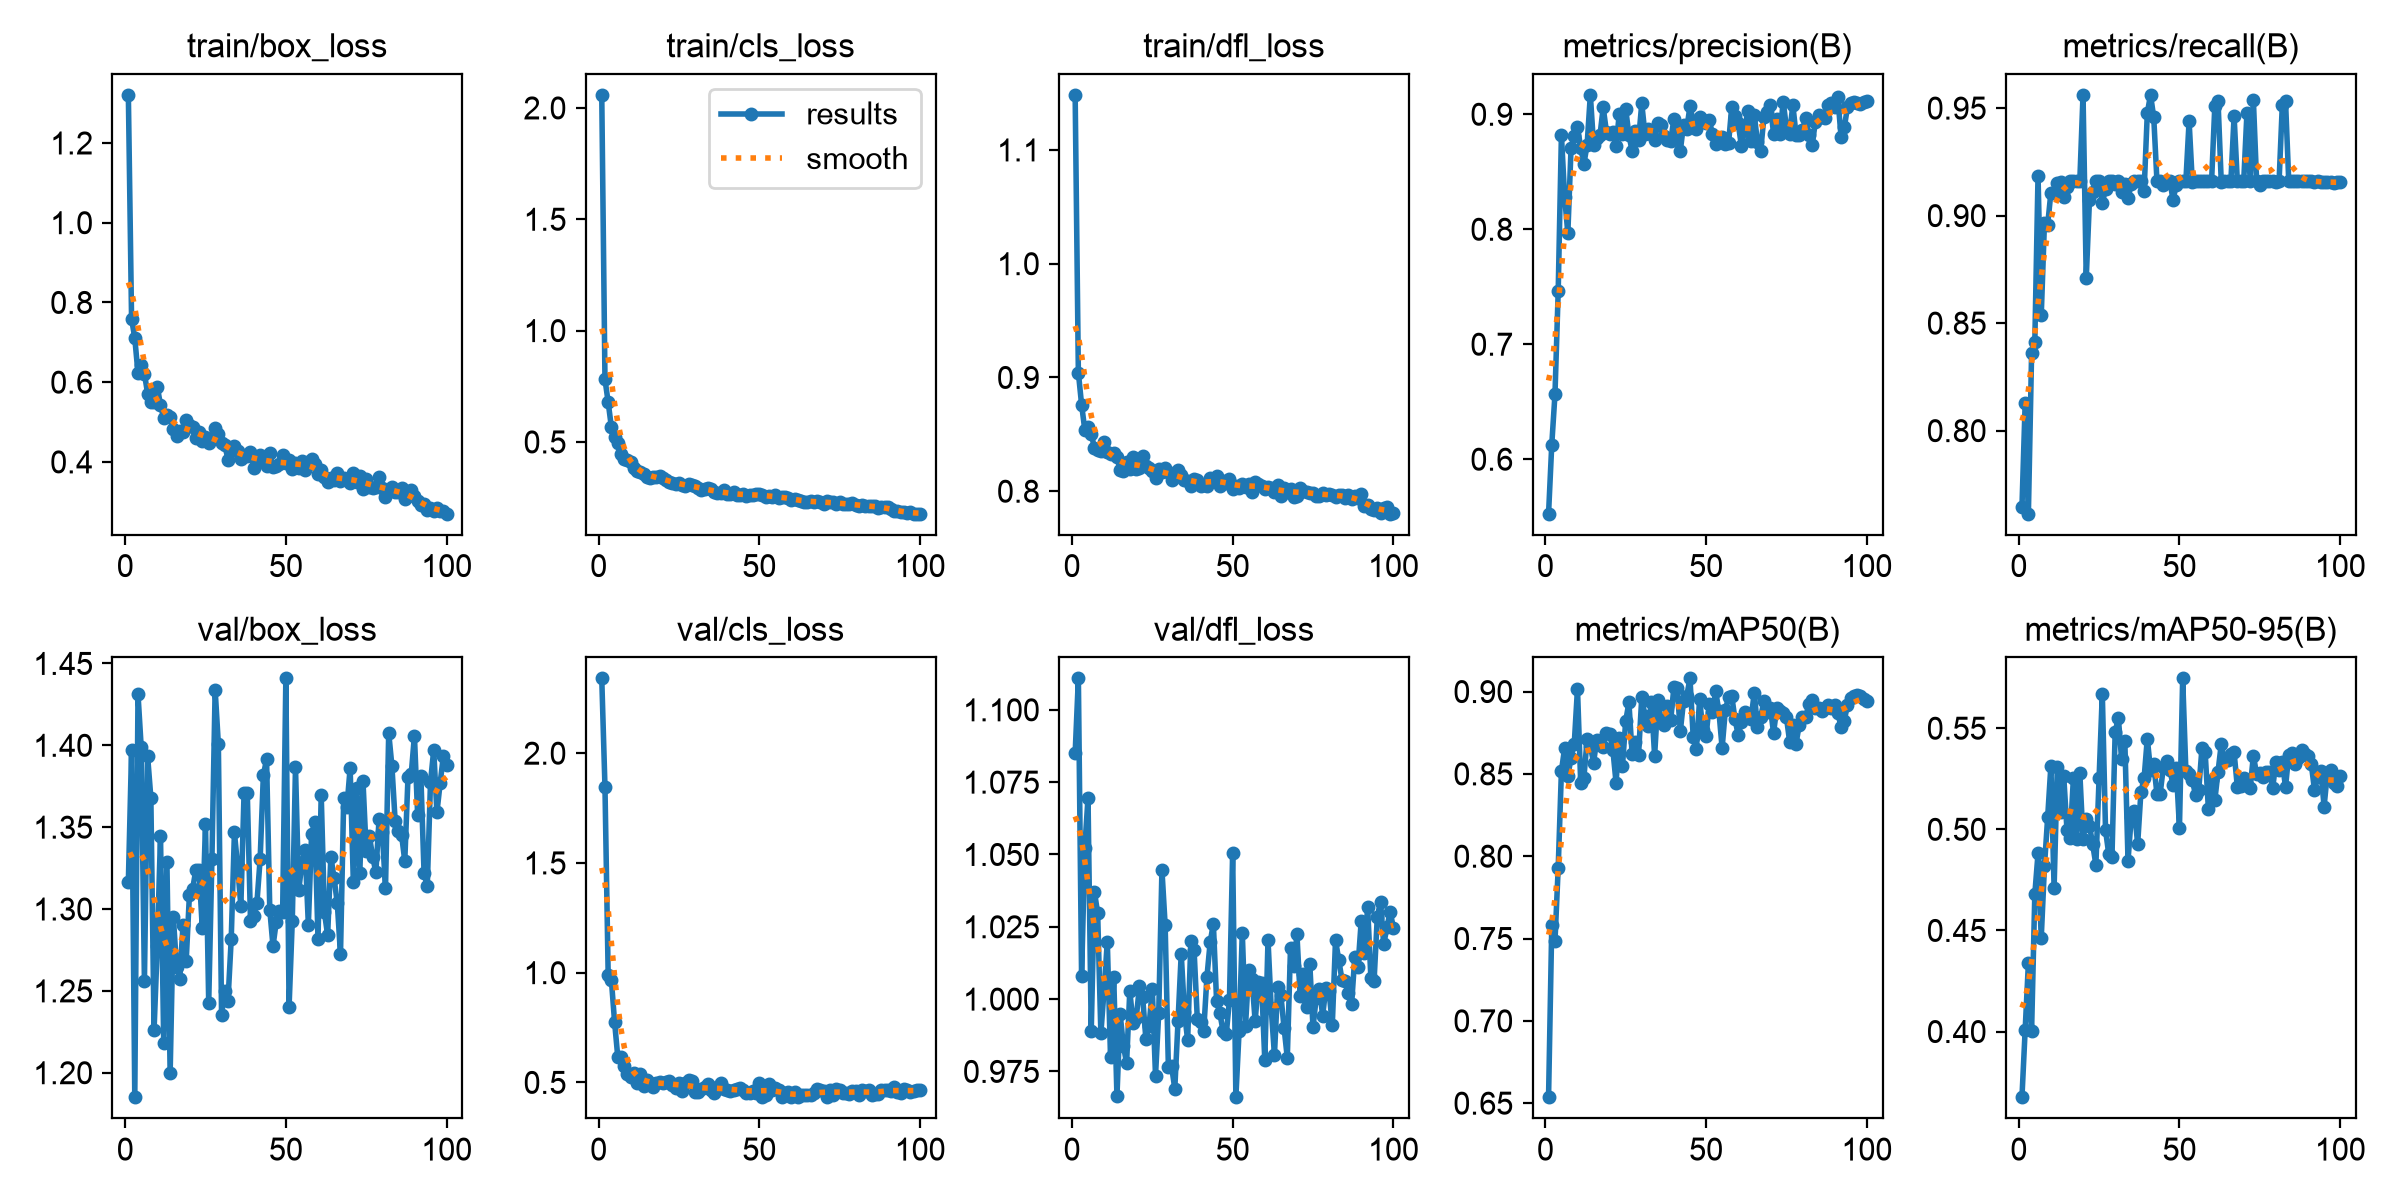

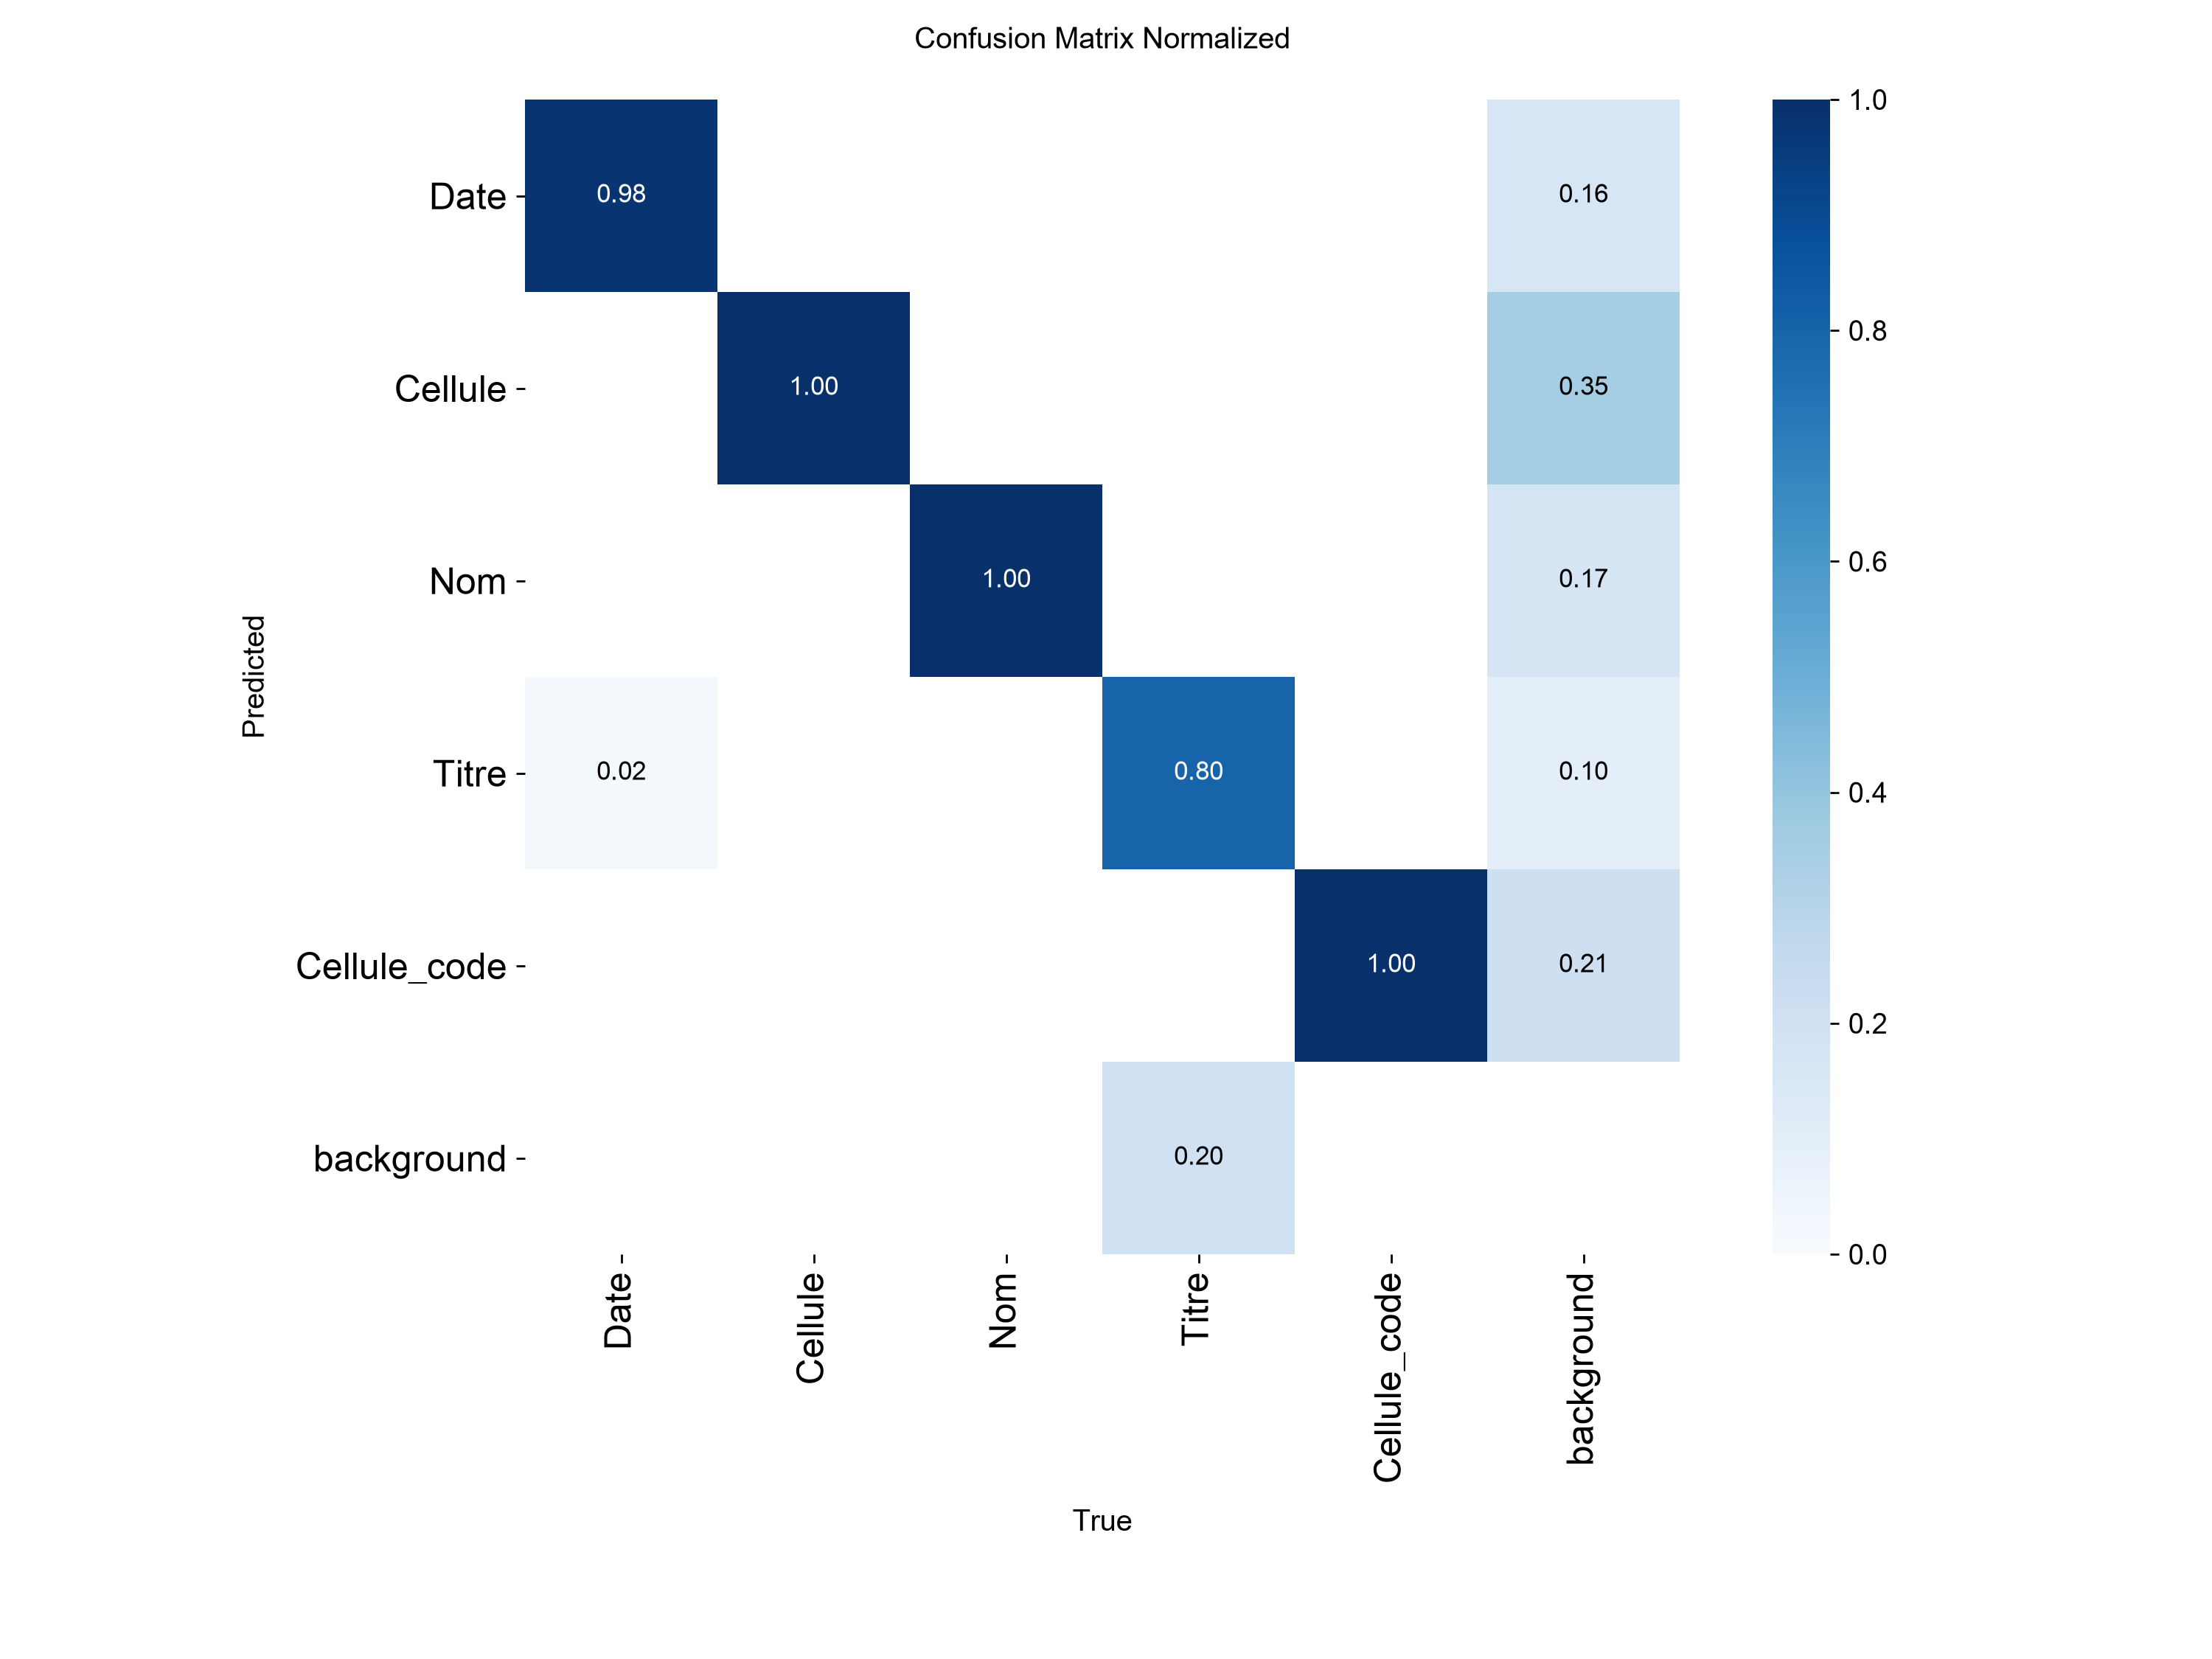

In [ ]:
from IPython.display import Image as ShowImage, display

display(ShowImage(filename=str(save_dir / "results.png")))
display(ShowImage(filename=str(save_dir / "confusion_matrix_normalized.png")))

## 10. Tester le modèle sur une image de validation

On demande au modèle de détecter les zones sur une image qu'il n'a **jamais vue** pendant l'entraînement.

`conf=0.25` est le **seuil de confiance** : le modèle donne un score à chaque boîte, et on ne garde que celles au-dessus de 25 %.
- en baissant le seuil, on rate moins de zones (meilleur rappel), mais on obtient plus de fausses boîtes ;
- en le montant, c'est l'inverse.

Change `VAL_INDEX` et `CONF` pour expérimenter.

img004.jpg — 57 boîtes : {'Cellule': 40, 'Nom': 9, 'Date': 7, 'Titre': 1}
img010.jpg — 39 boîtes : {'Cellule': 26, 'Nom': 6, 'Date': 6, 'Titre': 1}
img011.jpg — 46 boîtes : {'Nom': 8, 'Cellule': 32, 'Date': 5, 'Titre': 1}
img012.jpg — 32 boîtes : {'Cellule': 31, 'Titre': 1}
img025.jpg — 226 boîtes : {'Cellule_code': 191, 'Nom': 7, 'Date': 28}
img026.jpg — 32 boîtes : {'Cellule': 31, 'Titre': 1}
img031.jpg — 40 boîtes : {'Cellule': 25, 'Nom': 9, 'Date': 5, 'Titre': 1}
img037.jpg — 34 boîtes : {'Cellule': 33, 'Titre': 1}


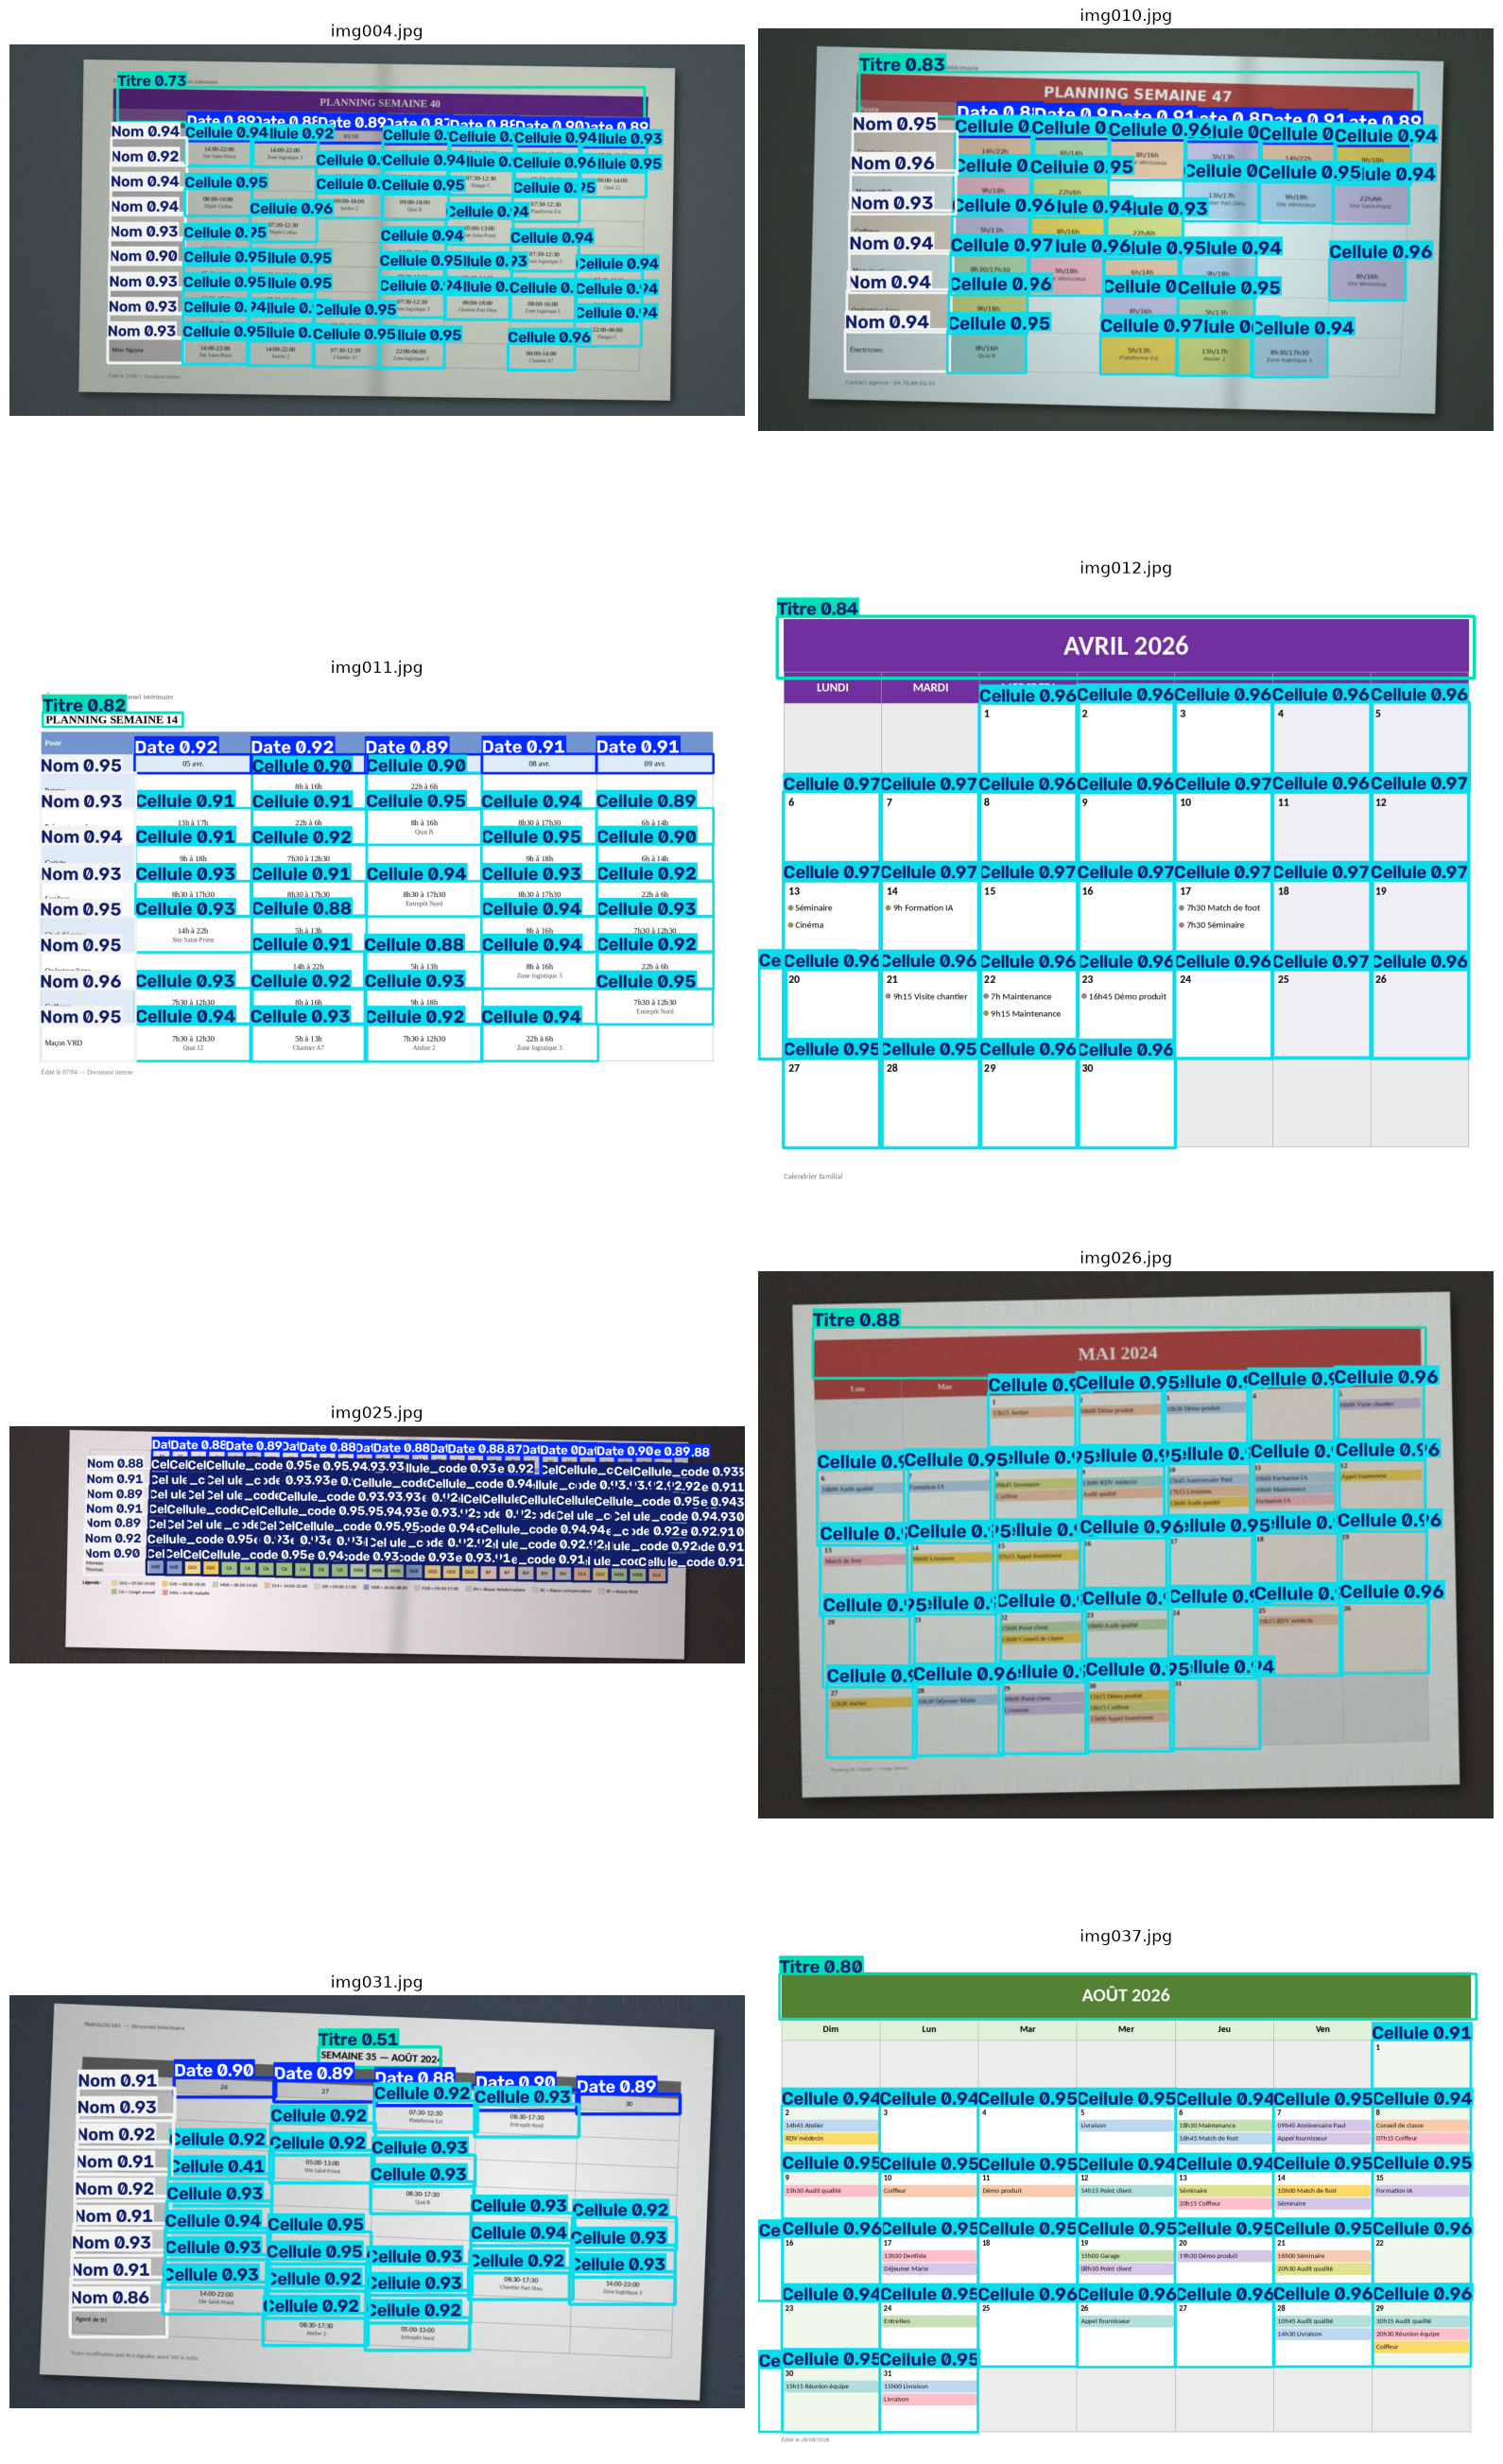

In [ ]:
CONF = 0.25  # seuil de confiance : on garde les boîtes dont le score dépasse 25 %
COLUMNS = 2  # nombre d'images par ligne dans la grille

val_images = sorted((DATASET / "images" / "val").rglob("*.jpg"))
predictions = YOLO(best_pt).predict([str(image) for image in val_images], conf=CONF, device="mps", verbose=False)

# Le décompte d'abord : combien de boîtes de chaque classe sur chaque image
for image, prediction in zip(val_images, predictions):
    counts = Counter(CLASS_NAMES[int(c)] for c in prediction.boxes.cls)
    print(f"{image.name} — {len(prediction.boxes)} boîtes : {dict(counts)}")

# Puis toutes les images dans une grille, deux par ligne
rows = (len(val_images) + COLUMNS - 1) // COLUMNS  # arrondi au-dessus : 8 images → 4 lignes
fig, axes = plt.subplots(rows, COLUMNS, figsize=(16, 7 * rows))
for ax, image, prediction in zip(axes.flat, val_images, predictions):
    ax.imshow(prediction.plot()[..., ::-1])  # plot() renvoie une image BGR (OpenCV) ; [..., ::-1] la remet en RGB
    ax.set_title(image.name)
for ax in axes.flat:
    ax.axis("off")  # enlève les graduations, et masque les cases vides si le nombre d'images est impair
plt.tight_layout()
plt.show()

## 11. Le champion (fin du jour 1, rôle du chef d'équipe)

Dans MLflow (*Experiments → flexistaff_team-magma*), cochez les runs `<prénom>_v1` de l'équipe puis cliquez sur **Compare**.
On choisit d'abord sur le **rappel**, puis sur le **mAP50** pour départager.

Le chef enregistre ensuite le meilleur modèle dans le **registre** avec l'alias `champion`. C'est lui que le notebook OCR
du jour 2 chargera (`flexistaff_team-magma@champion`).

Cette cellule est **commentée** : seul le chef la lance, avec le `RUN_ID` du run retenu.

In [ ]:
# from mlflow import MlflowClient
#
# NAME = f"flexistaff_{SQUAD}"
# RUN_ID = "<RUN_ID du meilleur run>"
# model_version = mlflow.register_model(f"runs:/{RUN_ID}/onnx", NAME)
# MlflowClient().set_registered_model_alias(NAME, "champion", model_version.version)